# Step 1- Loading the data

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
df = pd.read_csv('/content/sample_data/quickbite_customers.csv')
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   object 
 1   signup_date             2000 non-null   object 
 2   city                    2000 non-null   object 
 3   city_tier               2000 non-null   int64  
 4   gender                  1894 non-null   object 
 5   device_type             2000 non-null   object 
 6   acquisition_channel     2000 non-null   object 
 7   age                     1861 non-null   float64
 8   tenure_months           2000 non-null   float64
 9   app_sessions_per_month  2000 non-null   int64  
 10  delivery_time_min       1920 non-null   float64
 11  avg_order_value         1892 non-null   float64
 12  customer_rating         1742 non-null   float64
 13  discount_used_pct       1896 non-null   float64
 14  days_since_last_order   2000 non-null   

In [44]:
df.describe()

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
std,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856
min,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000


In [45]:
df.shape

(2000, 18)

In [46]:
df.isna().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


In [47]:
df.isna().mean()*100

,0
customer_id,0.00
signup_date,0.00
city,0.00
city_tier,0.00
gender,5.30
device_type,0.00
acquisition_channel,0.00
age,6.95
tenure_months,0.00
app_sessions_per_month,0.00


In [48]:
df_original = df.copy()
df = df.copy()

# Step 2 - Missing Value Imputation

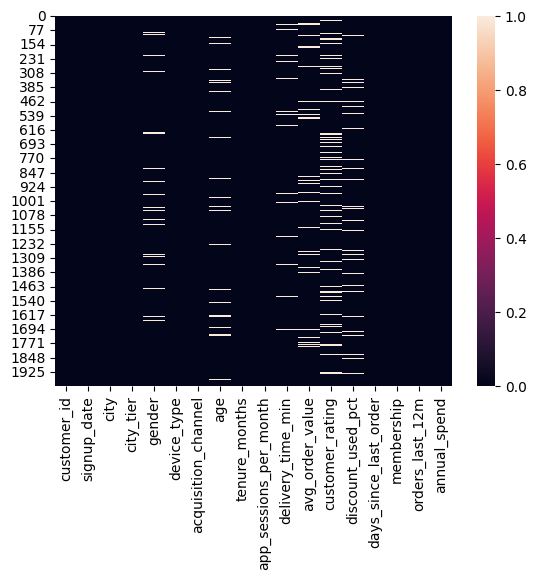

In [49]:
sns.heatmap(df.isna())
plt.show()

Here the Heatmap shows the missing values in each of the columns

In [50]:
df['age'].fillna(df['age'].median(), inplace=True)

/tmp/ipykernel_3193/1654433547.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)


We use median instead of mean to fill missing values in age because the median is less affected by outliers and extreme values.

In [51]:
df['delivery_time_min'].isna().sum()

np.int64(80)

In [52]:
df['delivery_time_min'].fillna(df['delivery_time_min'].median(),inplace=True)

/tmp/ipykernel_3193/1293337563.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['delivery_time_min'].fillna(df['delivery_time_min'].median(),inplace=True)


Since delivery_time_min is right-skewed, the mean will be pulled towards the higher delivery times (the long right tail).

In [53]:
df['avg_order_value'] = df['avg_order_value'].fillna(df.groupby('city_tier')['avg_order_value'].transform('median'))

For avg_order_value, we use group-wise median by city_tier instead of one global median because average order values may differ between city tiers.

In [54]:
df['avg_order_value'].isna().sum()

np.int64(0)

Difference Between the Global median and city_tier wise median

In [55]:
print("Global Median:", df['customer_rating'].median())

print(df.groupby('city_tier')['customer_rating'].median())

Global Median: 4.4
city_tier
1    4.4
2    4.5
3    4.4
Name: customer_rating, dtype: float64


In [56]:
df['rating_missing'] = df['customer_rating'].isnull()

In [57]:
df.groupby('rating_missing')['delivery_time_min'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
rating_missing,,,
False,1742,33.937572,31.4
True,258,41.255233,39.9


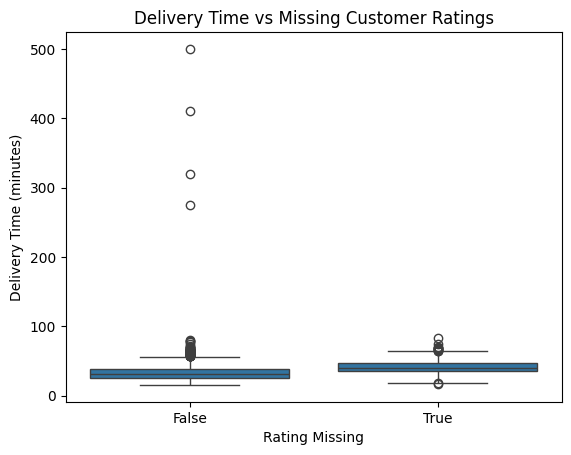

In [58]:
sns.boxplot(
    data=df,
    x='rating_missing',
    y='delivery_time_min'
)

plt.xlabel('Rating Missing')
plt.ylabel('Delivery Time (minutes)')
plt.title('Delivery Time vs Missing Customer Ratings')
plt.show()

Customers with missing ratings appear to have higher delivery times than customers who submitted ratings. The median delivery time is visibly higher for the missing-rating group. This suggests that rating missingness may be associated with delivery delays and should be investigated further.

In [59]:
df['customer_rating'] = df['customer_rating'].fillna(df.groupby('city_tier')['customer_rating'].transform('median'))

In [60]:
df['customer_rating'].isna().sum()

np.int64(0)

In [61]:
mean_value = df['discount_used_pct'].mean()
median_value = df['discount_used_pct'].median()

print("Mean:", mean_value)
print("Median:", median_value)

Mean: 22.499947257383962
Median: 22.4


For the discount percentage as we can see the mean and the median are almost same so we can fill the missing values with either of them

In [62]:
df['discount_used_pct'] = df['discount_used_pct'].fillna(df['discount_used_pct'].mean())

In [63]:
df['discount_used_pct'].isna().sum()

np.int64(0)

In [64]:
df['gender'] = df['gender'].fillna('Other')

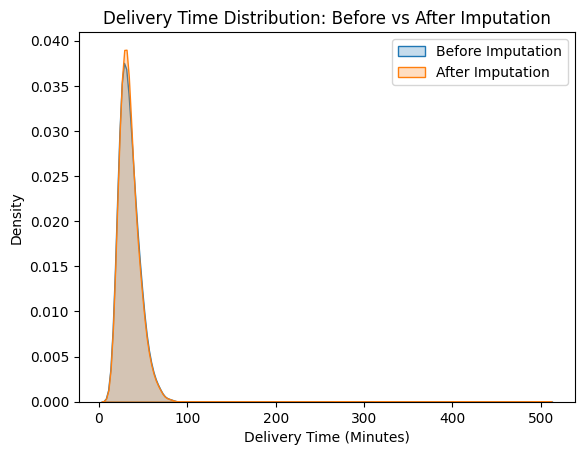

In [65]:
sns.kdeplot(
    df_original['delivery_time_min'].dropna(),
    label='Before Imputation',
    fill=True
)

sns.kdeplot(
    df['delivery_time_min'],
    label='After Imputation',
    fill=True
)

plt.title('Delivery Time Distribution: Before vs After Imputation')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Density')
plt.legend()
plt.show()

This KLD plot shows that median imputation has not significantly changed the overall distribution of delivery_time_min.

# Step 3- Outlier Detection and Removal

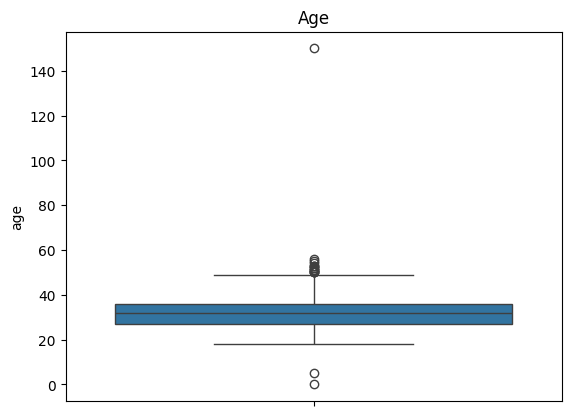

In [66]:
sns.boxplot(y=df['age'])
plt.title('Age')
plt.show()

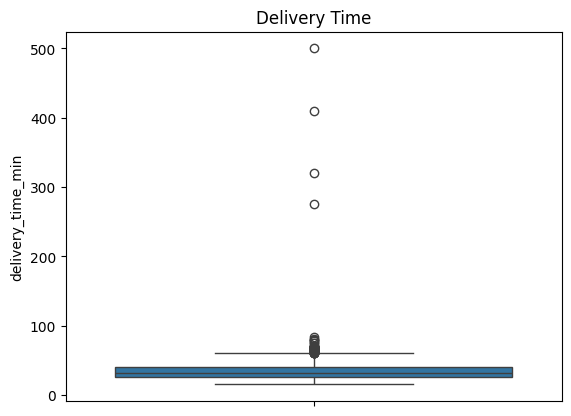

In [67]:
sns.boxplot(y=df['delivery_time_min'])
plt.title('Delivery Time')
plt.show()

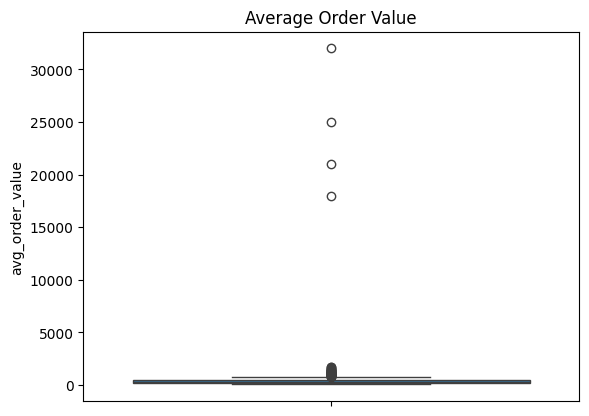

In [68]:
sns.boxplot(y=df['avg_order_value'])
plt.title('Average Order Value')
plt.show()

Apply the IQR method and Compare IQR and Z-score

In [69]:
from scipy.stats import zscore
Q1 = df['age'].quantile(.25)
Q3 = df['age'].quantile(.75)
IQR = Q3-Q1

#IQR
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_outliers_age = ((df['age']<lower) | (df['age']> upper)).sum()
print('IQR=', iqr_outliers_age)

#Zscore
zscores_age = zscore(df['age'], nan_policy = 'omit')
zscore_outliers_age = (abs(zscores_age)>3).sum()
print('Zscore=', zscore_outliers_age)


IQR= 18
Zscore= 6


In [70]:
display(df[
    (df['age'] < lower) |
    (df['age'] > upper)
])

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend,rating_missing
215,QB100215,2025-10-29,Jaipur,2,Female,Android,Organic,51.0,12.2,10,25.50,488.0,3.9,2.2,23.0,Basic,20,9652.0,False
245,QB100245,2023-10-18,Indore,3,Female,iOS,Influencer,5.0,37.0,13,32.25,569.0,4.6,26.1,1.0,Basic,17,8410.0,False
257,QB100257,2023-04-04,Mumbai,1,Male,Android,Influencer,56.0,43.5,16,29.60,518.0,4.9,17.3,0.0,Gold,17,10054.0,False
459,QB100459,2024-11-10,Pune,2,Female,Android,Referral,55.0,24.0,11,46.90,309.0,3.7,22.0,15.0,Basic,20,11055.0,False
572,QB100572,2024-05-29,Hyderabad,1,Male,Android,Organic,53.0,29.5,18,24.90,426.0,4.9,8.3,50.0,Gold,32,16332.0,False
606,QB100606,2023-09-07,Indore,3,Male,Android,Search Ads,50.0,38.3,13,40.50,583.0,3.8,15.4,19.0,Basic,17,9148.0,False
688,QB100688,2023-01-09,Jaipur,2,Female,iOS,Paid Social,50.0,46.4,14,47.40,416.0,5.0,25.1,15.0,Basic,61,22190.0,False
762,QB100762,2023-04-12,Mumbai,1,Male,iOS,Organic,51.0,43.3,17,41.80,230.0,4.0,20.6,37.0,Basic,24,4952.0,False
883,QB100883,2023-06-16,Hyderabad,1,Male,Web,Referral,52.0,41.1,10,35.20,200.0,4.6,12.9,15.0,Silver,10,2058.0,False
946,QB100946,2024-01-20,Jaipur,2,Male,Android,Influencer,52.0,33.8,14,26.60,404.0,4.6,19.9,2.0,Basic,24,8731.0,False


For Age- removed the outlier data

For Delivery Time- Kept the outliers as absurd delivery time can be a failure in delivering the order

For Average Order Value- Kept the outliers as more value can be that it can be a VIP customer

In [71]:
df=df[(df['age']>=lower) & (df['age']<=upper)]

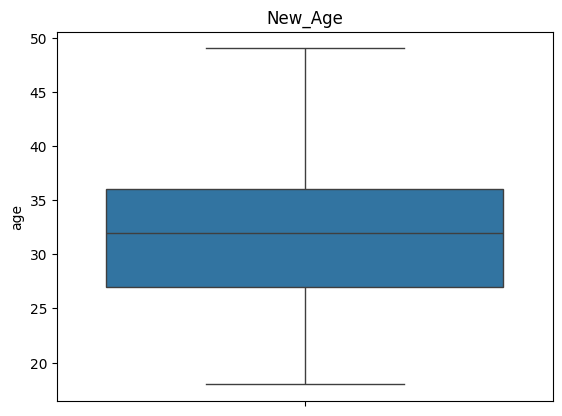

In [72]:
sns.boxplot(y=df['age'])
plt.title('New_Age')
plt.show()

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1982 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             1982 non-null   object 
 1   signup_date             1982 non-null   object 
 2   city                    1982 non-null   object 
 3   city_tier               1982 non-null   int64  
 4   gender                  1982 non-null   object 
 5   device_type             1982 non-null   object 
 6   acquisition_channel     1982 non-null   object 
 7   age                     1982 non-null   float64
 8   tenure_months           1982 non-null   float64
 9   app_sessions_per_month  1982 non-null   int64  
 10  delivery_time_min       1982 non-null   float64
 11  avg_order_value         1982 non-null   float64
 12  customer_rating         1982 non-null   float64
 13  discount_used_pct       1982 non-null   float64
 14  days_since_last_order   1982 non-null   float

# Step 4- Distribution Shapes with KDE Plots Plot a histogram with a KDE curve

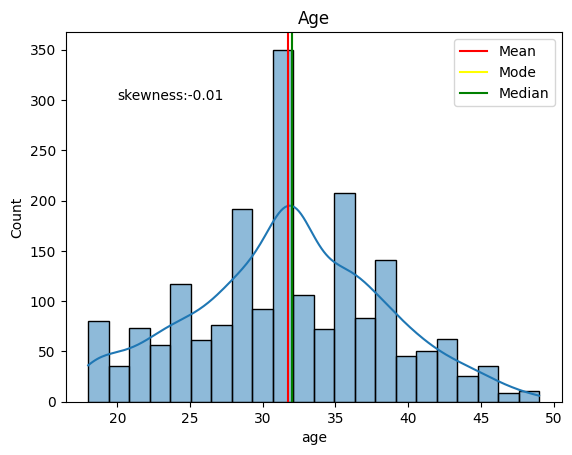

In [74]:
mean= df['age'].mean()
median = df['age'].median()
mode = df['age'].mode()
skewwness = df['age'].skew()
sns.histplot(data=df, x='age', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(20,300,f'skewness:{ round(skewwness,2)}')
plt.title('Age')
plt.show()

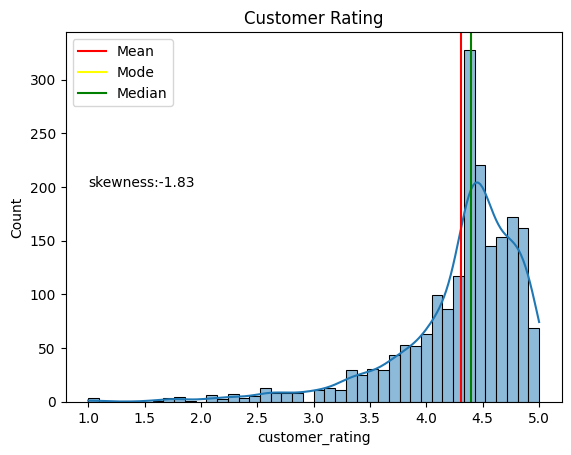

In [75]:
mean= df['customer_rating'].mean()
median = df['customer_rating'].median()
mode = df['customer_rating'].mode()
skewwness = df['customer_rating'].skew()
sns.histplot(data=df, x='customer_rating', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(1,200,f'skewness:{ round(skewwness,2)}')
plt.title('Customer Rating')
plt.show()

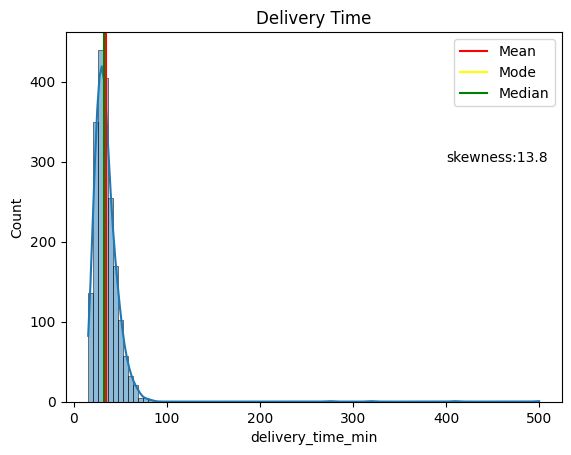

In [76]:
mean= df['delivery_time_min'].mean()
median = df['delivery_time_min'].median()
mode = df['delivery_time_min'].mode()
skewwness = df['delivery_time_min'].skew()
sns.histplot(data=df, x='delivery_time_min', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(400,300,f'skewness:{ round(skewwness,2)}')
plt.title('Delivery Time')
plt.show()

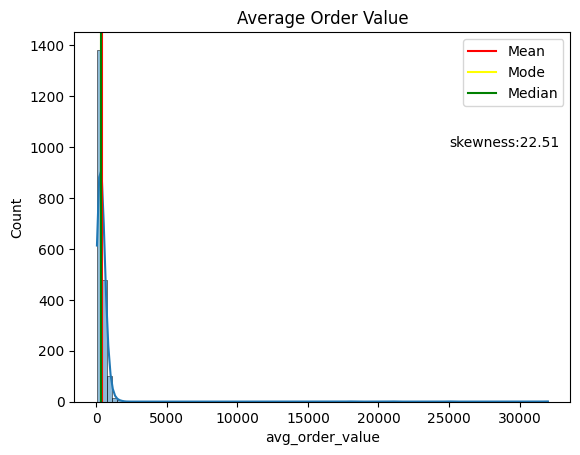

In [77]:
mean= df['avg_order_value'].mean()
median = df['avg_order_value'].median()
mode = df['avg_order_value'].mode()
skewwness = df['avg_order_value'].skew()
sns.histplot(data=df, x='avg_order_value', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(25000,1000,f'skewness:{ round(skewwness,2)}')
plt.title('Average Order Value')
plt.show()

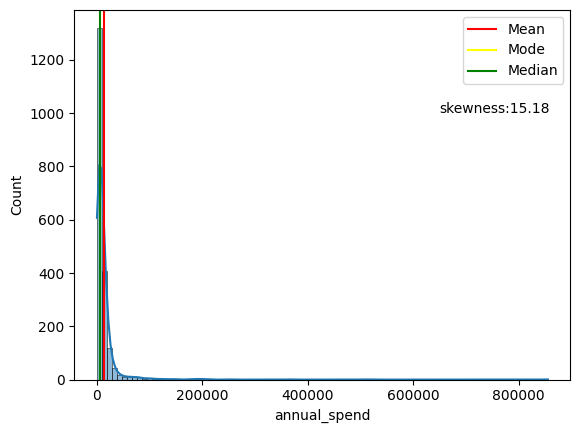

In [78]:
mean= df['annual_spend'].mean()
median = df['annual_spend'].median()
mode = df['annual_spend'].mode()
skewwness = df['annual_spend'].skew()
sns.histplot(data=df, x='annual_spend', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(650000,1000,f'skewness:{ round(skewwness,2)}')
plt.show()

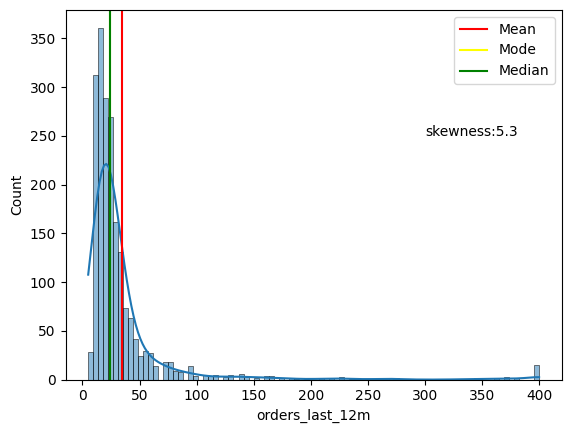

In [79]:
mean= df['orders_last_12m'].mean()
median = df['orders_last_12m'].median()
mode = df['orders_last_12m'].mode()
skewwness = df['orders_last_12m'].skew()
sns.histplot(data=df, x='orders_last_12m', kde=True)
plt.axvline(mean,color='red',label='Mean')
plt.axvline(median,color='Yellow',label='Mode')
plt.axvline(median,color='Green',label='Median')
plt.legend()
plt.text(300,250,f'skewness:{ round(skewwness,2)}')
plt.show()

# Step 5- Relationships Between Variables

In [125]:
#Selecting the numerical Data

numeric_df = df.select_dtypes(include='number')

Covariance tells us whether two variables move together.


* Positive covariance: Both variables tend to increase together.

* Negative covariance: When one increases, the other tends to decrease.

* Near-zero covariance: Little linear co-movement.




In [81]:
covarience = numeric_df.cov()
covarience

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,0.596527,0.063175,0.109537,0.057339,1.679998,-4.941539e+01,-0.001301,-0.146498,0.375325,9.130662e-01,-1.276839e+02
age,0.063175,43.462077,0.286504,-0.245880,7.763370,-2.550143e+02,-0.024350,-15.061175,-2.108458,2.895195e+00,5.742288e+03
tenure_months,0.109537,0.286504,99.455033,-0.214868,1.848733,-5.062909e+02,0.117261,-0.104472,-3.209101,-8.693608e+00,-3.774157e+03
app_sessions_per_month,0.057339,-0.245880,-0.214868,14.346901,-1.138477,4.298883e+00,0.017638,-1.008485,1.769874,1.410538e+01,9.778254e+03
delivery_time_min,1.679998,7.763370,1.848733,-1.138477,367.536928,-3.248222e+02,0.345308,-3.539544,-6.946195,-1.421272e+01,-7.678533e+03
avg_order_value,-49.415391,-255.014347,-506.290852,4.298883,-324.822217,1.227165e+06,10.326611,-63.319987,-141.192564,-7.362114e+02,1.253642e+06
customer_rating,-0.001301,-0.024350,0.117261,0.017638,0.345308,1.032661e+01,0.323584,-0.004912,-0.708029,-1.908031e-01,-1.249128e+01
discount_used_pct,-0.146498,-15.061175,-0.104472,-1.008485,-3.539544,-6.331999e+01,-0.004912,85.243168,-5.605912,6.428822e+00,-8.312402e+03
days_since_last_order,0.375325,-2.108458,-3.209101,1.769874,-6.946195,-1.411926e+02,-0.708029,-5.605912,361.391866,7.042477e+00,-1.006805e+04
orders_last_12m,0.913066,2.895195,-8.693608,14.105377,-14.212723,-7.362114e+02,-0.190803,6.428822,7.042477,2.443700e+03,1.091589e+06


<Axes: >

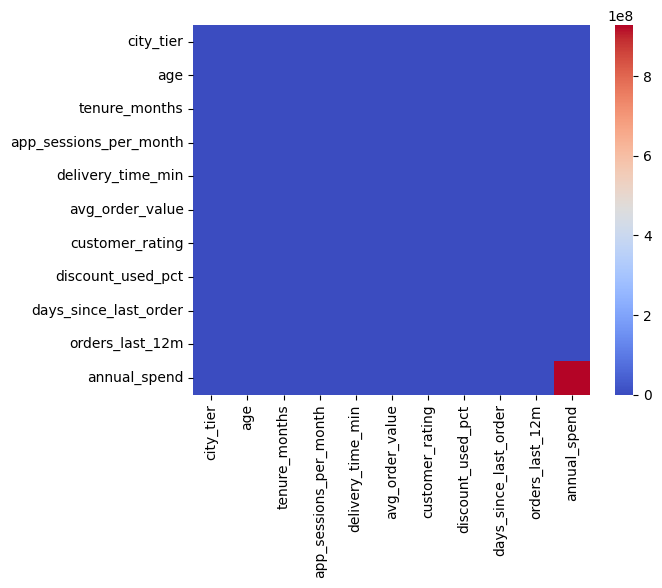

In [82]:
sns.heatmap(data= covarience,cmap='coolwarm')

Correlation measures the strength and direction of a linear relationship.

It ranges from -1 to +1.

In [83]:
correlation = numeric_df.corr()
correlation

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,1.000000,0.012407,0.014221,0.019600,0.113460,-0.057756,-0.002962,-0.020544,0.025563,0.023915,-0.005427
age,0.012407,1.000000,0.004358,-0.009847,0.061425,-0.034919,-0.006493,-0.247442,-0.016824,0.008884,0.028592
tenure_months,0.014221,0.004358,1.000000,-0.005688,0.009670,-0.045828,0.020670,-0.001135,-0.016927,-0.017634,-0.012423
app_sessions_per_month,0.019600,-0.009847,-0.005688,1.000000,-0.015678,0.001025,0.008186,-0.028838,0.024580,0.075332,0.084742
delivery_time_min,0.113460,0.061425,0.009670,-0.015678,1.000000,-0.015295,0.031664,-0.019997,-0.019059,-0.014997,-0.013148
avg_order_value,-0.057756,-0.034919,-0.045828,0.001025,-0.015295,1.000000,0.016388,-0.006191,-0.006705,-0.013444,0.037148
customer_rating,-0.002962,-0.006493,0.020670,0.008186,0.031664,0.016388,1.000000,-0.000935,-0.065474,-0.006785,-0.000721
discount_used_pct,-0.020544,-0.247442,-0.001135,-0.028838,-0.019997,-0.006191,-0.000935,1.000000,-0.031939,0.014086,-0.029554
days_since_last_order,0.025563,-0.016824,-0.016927,0.024580,-0.019059,-0.006705,-0.065474,-0.031939,1.000000,0.007494,-0.017385
orders_last_12m,0.023915,0.008884,-0.017634,0.075332,-0.014997,-0.013444,-0.006785,0.014086,0.007494,1.000000,0.724858


Why is correlation easier to interpret than covariance?

Correlation is standardized between -1 and +1, making its strength and direction easy to understand. Covariance depends on the units and scales of the variables, making comparisons difficult.

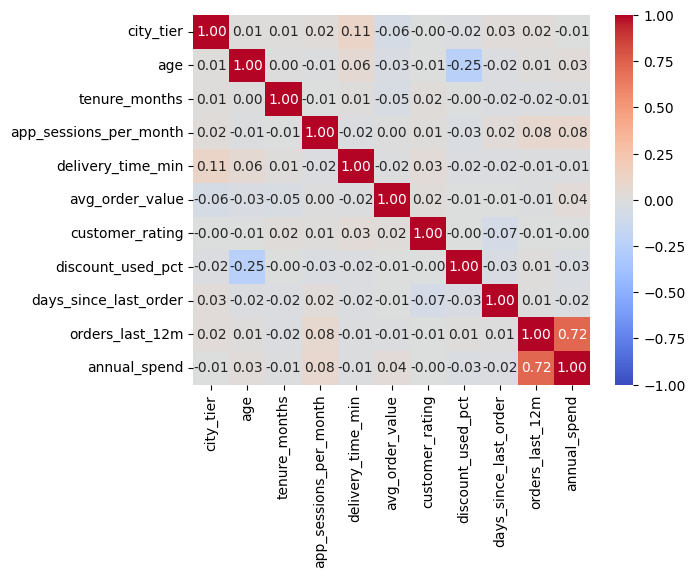

In [84]:
sns.heatmap(data=correlation, cmap='coolwarm', annot=True, vmax=1,vmin=-1,fmt='.2f')
plt.show()

Heatmap of correlation matrix

A heatmap helps us visually identify relationships between numerical variables.

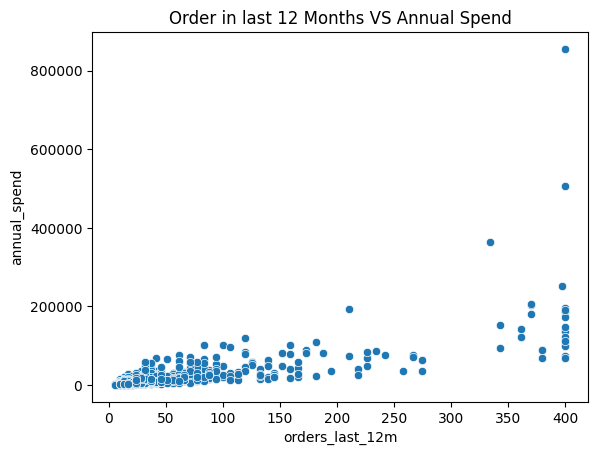

In [85]:
sns.scatterplot(data = df, x='orders_last_12m', y = 'annual_spend')
plt.title('Order in last 12 Months VS Annual Spend')
plt.show()

The scatter plot indicates a positive relationship between the number of orders placed in the last 12 months and annual customer spending.

A few extreme high-spending customers are also visible, which may represent valuable VIP customers.

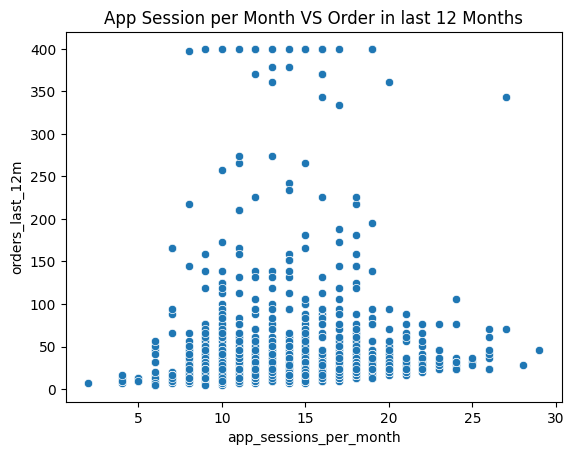

In [86]:
sns.scatterplot(data = df, x='app_sessions_per_month', y = 'orders_last_12m')
plt.title('App Session per Month VS Order in last 12 Months')
plt.show()

scatter plot shows a weak-to-moderate positive relationship between app_sessions_per_month and orders_last_12m, although the relationship is not very clear visually.

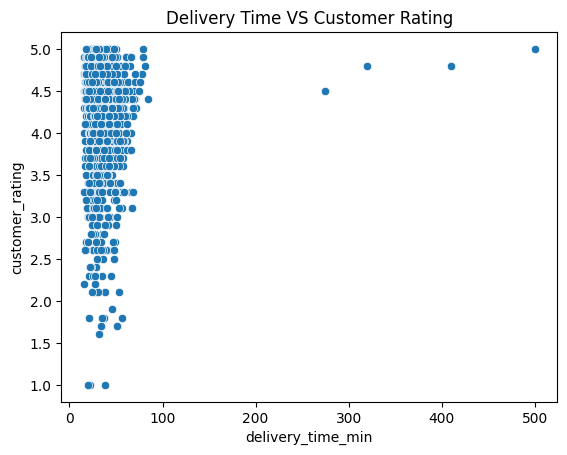

In [87]:
sns.scatterplot(data = df, x='delivery_time_min', y = 'customer_rating')
plt.title('Delivery Time VS Customer Rating')
plt.show()

The scatter plot shows no clear linear relationship between delivery time and customer ratings.

Most customer ratings are concentrated between 3.5 and 5, despite variations in delivery time.

In [88]:
df['signup_date'] = pd.to_datetime(df['signup_date'])

In [89]:
df['signup_month'] = df['signup_date'].dt.month

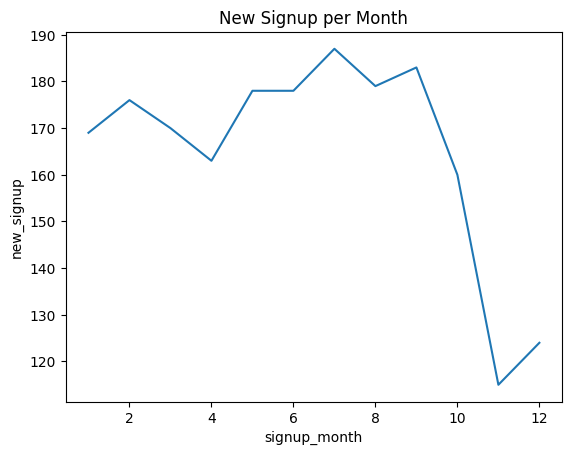

In [90]:
monthly_signup = df.groupby('signup_month').size().reset_index(name='new_signup')
sns.lineplot(data=monthly_signup, x='signup_month',y='new_signup')
plt.title('New Signup per Month')
plt.show()


Customer signups generally remain stable between January and April, followed by an increase from May to September. July records the highest number of signups

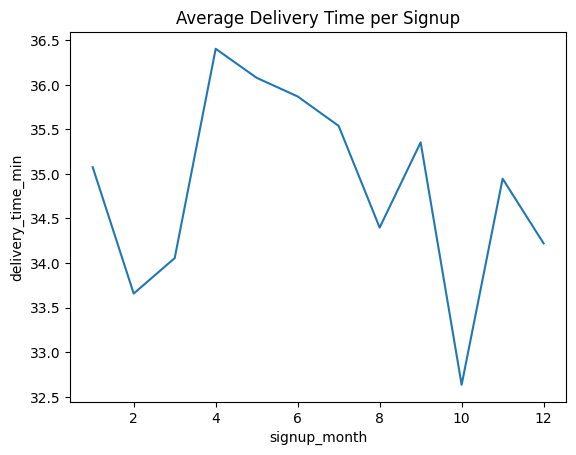

In [91]:
monthly_delivery = df.groupby('signup_month')['delivery_time_min'].mean().reset_index()
sns.lineplot(data=monthly_delivery, x='signup_month', y='delivery_time_min')
plt.title('Average Delivery Time per Signup')
plt.show()

The company should investigate why delivery times were relatively high during Months 4–7

The sudden increase in Month 11 should be investigated to identify possible operational challenges.

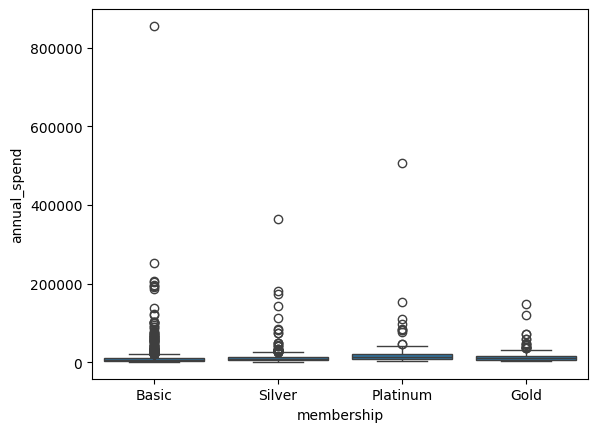

In [92]:
sns.boxplot(data=df, x='membership', y='annual_spend')
plt.show()

Basic members show a large number of outliers, including the highest spending outlier of approximately 850,000. This suggests that some Basic members are exceptionally high spenders despite having an entry-level membership.

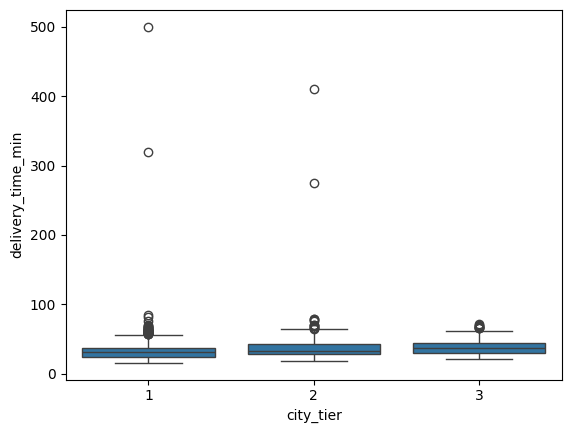

In [93]:
sns.boxplot(data=df, x='city_tier', y='delivery_time_min')
plt.show()

For Tier 1 cities the delivery time is more as compaired to tier 2 and 3 that need to checked.

In [126]:
annual_corr = correlation['annual_spend'].drop('annual_spend')

annual_corr = annual_corr.sort_values(
    key=abs,
    ascending=False
)

print(annual_corr)

orders_last_12m           0.724858
app_sessions_per_month    0.084742
avg_order_value           0.037148
discount_used_pct        -0.029554
age                       0.028592
days_since_last_order    -0.017385
delivery_time_min        -0.013148
tenure_months            -0.012423
city_tier                -0.005427
customer_rating          -0.000721
Name: annual_spend, dtype: float64


In [127]:
strongest_variable = annual_corr.abs().idxmax()

strongest_value = annual_corr[strongest_variable]

print("Strongest Variable:", strongest_variable)
print("Correlation:", strongest_value)

Strongest Variable: orders_last_12m
Correlation: 0.7248582085481005


So here we can see the strongest relation of annual_spend is with order_last_12m

# Step 6- Encoding Categorical Variables

Label Encoding on Membership Order

In [94]:
membership_order = {
    'Basic':1,
    'Silver':2,
    'Platinum':3,
    'Gold':4
}

df['membership']= df['membership'].map(membership_order)

In [95]:
df['membership'].isna().sum()

np.int64(0)

One Hot Encoding on Device Type

In [96]:
df['device_type'].value_counts()

,count
device_type,
Android,1162
iOS,648
Web,172


In [97]:
df=pd.get_dummies(
    df,
    columns=['device_type'],
    dtype=int
)

Target Encoding on Annual Spend

In [98]:
city_mean = df.groupby('city')['annual_spend'].mean()

df['city_encoded'] = df['city'].map(city_mean)

In [99]:
df

,customer_id,signup_date,city,city_tier,gender,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,...,days_since_last_order,membership,orders_last_12m,annual_spend,rating_missing,signup_month,device_type_Android,device_type_Web,device_type_iOS,city_encoded
0,QB100000,2023-11-27,Lucknow,2,Female,Referral,21.0,35.6,13,45.3,...,4.0,1,17,8675.0,True,11,1,0,0,14007.401361
1,QB100001,2025-05-26,Bengaluru,1,Female,Influencer,43.0,17.4,11,21.9,...,13.0,1,24,7896.0,False,5,0,0,1,12004.006803
2,QB100002,2023-02-06,Indore,3,Male,Referral,39.0,45.4,12,47.9,...,1.0,1,17,1826.0,False,2,0,0,1,10759.593103
3,QB100003,2024-04-09,Jaipur,2,Female,Paid Social,34.0,31.2,13,26.4,...,7.0,1,379,90202.0,True,4,1,0,0,10343.921429
4,QB100004,2025-04-12,Mumbai,1,Male,Search Ads,33.0,18.9,17,19.4,...,12.0,1,17,2773.0,False,4,1,0,0,12072.455696
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,Male,Influencer,18.0,39.4,9,42.7,...,6.0,1,13,2704.0,False,8,0,0,1,10343.921429
1996,QB101996,2025-06-07,Delhi,1,Male,Search Ads,29.0,17.0,7,20.7,...,6.0,1,17,3723.0,False,6,0,0,1,12177.946488
1997,QB101997,2025-10-15,Bengaluru,1,Male,Paid Social,45.0,12.7,18,38.0,...,1.0,2,24,13736.0,True,10,1,0,0,12004.006803
1998,QB101998,2025-02-22,Indore,3,Male,Influencer,32.0,20.5,21,68.8,...,8.0,3,37,14368.0,False,2,0,0,1,10759.593103


Why not use label encoding for city?
If we assign numerical values alphabetically:
- Bangalore = 0
- Delhi = 1
- Mumbai = 2

The algorithm may interpret these values as having an order or numerical relationship.

However, cities do not have any natural ranking. Therefore, alphabetical label encoding would be misleading.

# Step 7- Central Tendency and Percentiles

In [100]:
# Mean
df[['age', 'orders_last_12m', 'annual_spend']].mean()

,0
age,31.749243
orders_last_12m,34.920283
annual_spend,13020.973764


In [101]:
# Median
df[['age', 'orders_last_12m', 'annual_spend']].median()

,0
age,32.0
orders_last_12m,24.0
annual_spend,7117.5


In [102]:
# Mode
df[['age', 'orders_last_12m', 'annual_spend']].mode()

,age,orders_last_12m,annual_spend
0,32.0,17.0,2916.0
1,NaN,NaN,3772.0
2,NaN,NaN,4741.0
3,NaN,NaN,5920.0
4,NaN,NaN,6275.0
5,NaN,NaN,11106.0


In [103]:
df[['membership']].mode()

,membership
0,1


In [104]:
mean_spend = df['annual_spend'].mean()
median_spend = df['annual_spend'].median()

print("Mean:", mean_spend)
print("Median:", median_spend)
print("Difference:", mean_spend - median_spend)

Mean: 13020.973763874874
Median: 7117.5
Difference: 5903.473763874874


The mean is higher as a small number of customers are spending exceptionally high amounts. These high-spending customers increase the overall average.

In [105]:
percentile = [0.1,0.25,0.50,0.75,0.90,0.95,0.99]
df['delivery_time_min'].quantile(percentile)

,delivery_time_min
0.10,22.100
0.25,26.500
0.50,32.250
0.75,40.000
0.90,49.300
0.95,55.400
0.99,68.638


In [106]:
df['annual_spend'].quantile(percentile)

,annual_spend
0.10,2509.60
0.25,4080.50
0.50,7117.50
0.75,12785.75
0.90,22491.30
0.95,35500.35
0.99,109721.82


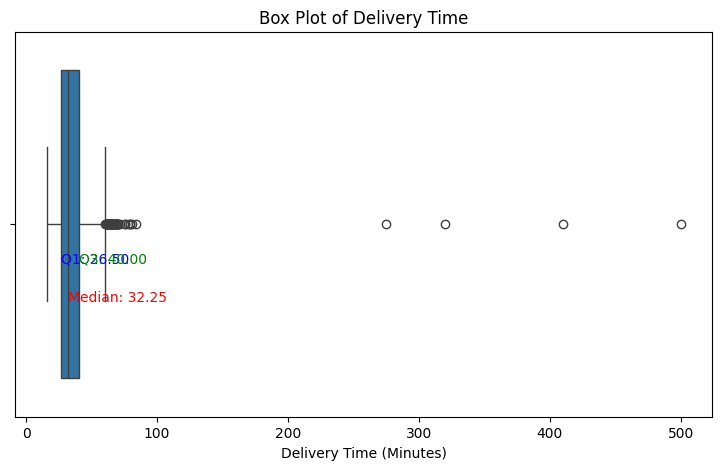

In [107]:
Q1 = df['delivery_time_min'].quantile(0.25)
Q2 = df['delivery_time_min'].quantile(0.50)
Q3 = df['delivery_time_min'].quantile(0.75)

plt.figure(figsize=(9, 5))

sns.boxplot(x=df['delivery_time_min'])

plt.text(Q1, 0.1, f'Q1: {Q1:.2f}', color='blue')
plt.text(Q2, 0.2, f'Median: {Q2:.2f}', color='red')
plt.text(Q3, 0.1, f'Q3: {Q3:.2f}', color='green')

plt.title('Box Plot of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.show()

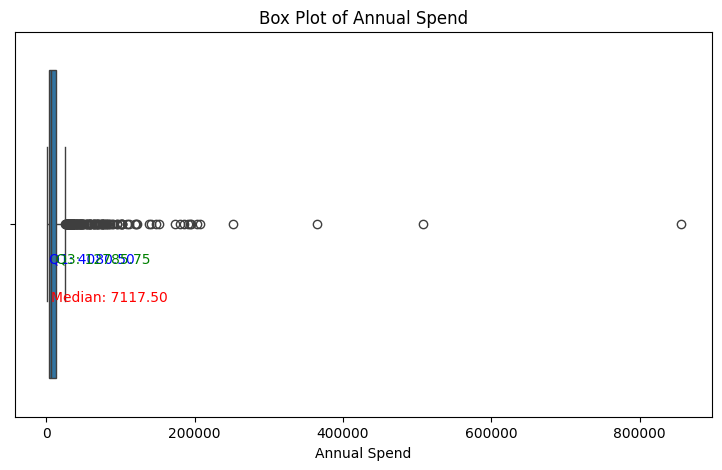

In [108]:
Q1 = df['annual_spend'].quantile(0.25)
Q2 = df['annual_spend'].quantile(0.50)
Q3 = df['annual_spend'].quantile(0.75)

plt.figure(figsize=(9, 5))

sns.boxplot(x=df['annual_spend'])

plt.text(Q1, 0.1, f'Q1: {Q1:.2f}', color='blue')
plt.text(Q2, 0.2, f'Median: {Q2:.2f}', color='red')
plt.text(Q3, 0.1, f'Q3: {Q3:.2f}', color='green')

plt.title('Box Plot of Annual Spend')
plt.xlabel('Annual Spend')
plt.show()


In [128]:

# Calculate 90th percentile of delivery time
p90_delivery = df['delivery_time_min'].quantile(0.90)

print("90th Percentile Delivery Time:", round(p90_delivery, 2), "minutes")

print(
    f"90% of customers receive their orders within "
    f"{p90_delivery:.2f} minutes."
)


90th Percentile Delivery Time: 49.3 minutes
90% of customers receive their orders within 49.30 minutes.


So here we can see that maximum i.e. 90% of the customers are getting their order within 50 min

# Step 8- Pareto Distribution and the 80/20 Rule

Sort customers by Annual Spending

In [129]:

# Sort customers by annual spending in descending order
pareto_df = df[['annual_spend']].dropna().copy()

pareto_df = pareto_df.sort_values(
    by='annual_spend',
    ascending=False
).reset_index(drop=True)

# Create customer rank
pareto_df['customer_rank'] = range(1, len(pareto_df) + 1)

# Display top 10 customers
display(pareto_df.head(10))


,annual_spend,customer_rank
0,855443.0,1
1,507406.0,2
2,364740.0,3
3,251922.0,4
4,207118.0,5
5,203782.0,6
6,195694.0,7
7,193862.0,8
8,191718.0,9
9,185908.0,10


Calculate Cumulative Revenue Share

In [130]:

# Calculate total revenue
total_revenue = pareto_df['annual_spend'].sum()

# Calculate cumulative revenue
pareto_df['cumulative_revenue'] = (
    pareto_df['annual_spend'].cumsum()
)

# Calculate individual revenue share
pareto_df['revenue_share_pct'] = (
    pareto_df['annual_spend'] / total_revenue * 100
)

# Calculate cumulative revenue share
pareto_df['cumulative_share_pct'] = (
    pareto_df['cumulative_revenue'] / total_revenue * 100
)

# Calculate cumulative percentage of customers
pareto_df['cumulative_customer_pct'] = (
    pareto_df['customer_rank'] / len(pareto_df) * 100
)

# Display results
display(pareto_df.head(15))


,annual_spend,customer_rank,cumulative_revenue,revenue_share_pct,cumulative_share_pct,cumulative_customer_pct
0,855443.0,1,855443.0,3.314698,3.314698,0.050454
1,507406.0,2,1362849.0,1.966113,5.280811,0.100908
2,364740.0,3,1727589.0,1.413306,6.694117,0.151362
3,251922.0,4,1979511.0,0.976155,7.670273,0.201816
4,207118.0,5,2186629.0,0.802547,8.472820,0.252270
5,203782.0,6,2390411.0,0.789621,9.262441,0.302725
6,195694.0,7,2586105.0,0.758281,10.020723,0.353179
7,193862.0,8,2779967.0,0.751183,10.771905,0.403633
8,191718.0,9,2971685.0,0.742875,11.514780,0.454087
9,185908.0,10,3157593.0,0.720362,12.235143,0.504541


In [135]:

# Find the number of customers needed to reach
# a particular revenue contribution

def customers_for_revenue(target_pct, data):
    n = (
        data['cumulative_share_pct'] >= target_pct
    ).idxmax() + 1

    customer_pct = n / len(data) * 100

    return n, customer_pct


# Calculate customers contributing 50% revenue
customers_50, pct_customers_50 = customers_for_revenue(
    50, pareto_df
)

# Calculate customers contributing 80% revenue
customers_80, pct_customers_80 = customers_for_revenue(
    80, pareto_df
)

print("Total Customers:", len(pareto_df))

print("\nRevenue Contribution Analysis")

print(
    f"50% Revenue is contributed by "
    f"{customers_50} customers "
    f"({pct_customers_50:.2f}% of customers)"
)

print(
    f"80% Revenue is contributed by "
    f"{customers_80} customers "
    f"({pct_customers_80:.2f}% of customers)"
)


Total Customers: 1982

Revenue Contribution Analysis
50% Revenue is contributed by 234 customers (11.81% of customers)
80% Revenue is contributed by 852 customers (42.99% of customers)


In [136]:

import numpy as np

# Calculate the number of customers in the top 20%
top_20_count = int(np.ceil(len(pareto_df) * 0.20))

# Select top 20% customers
top_20_customers = pareto_df.head(top_20_count)

# Calculate their revenue contribution
top_20_revenue = top_20_customers['annual_spend'].sum()

top_20_share = (
    top_20_revenue / total_revenue * 100
)

print("Top 20% Customer Analysis")
print("Number of customers:", top_20_count)
print("Revenue contribution:", round(top_20_share, 2), "%")

# Compare with classic Pareto principle
if top_20_share > 80:
    print("The dataset shows stronger concentration than the classic 80/20 rule.")
elif top_20_share < 80:
    print("The dataset shows lower concentration than the classic 80/20 rule.")
else:
    print("The dataset follows the classic 80/20 rule.")


Top 20% Customer Analysis
Number of customers: 397
Revenue contribution: 60.76 %
The dataset shows lower concentration than the classic 80/20 rule.


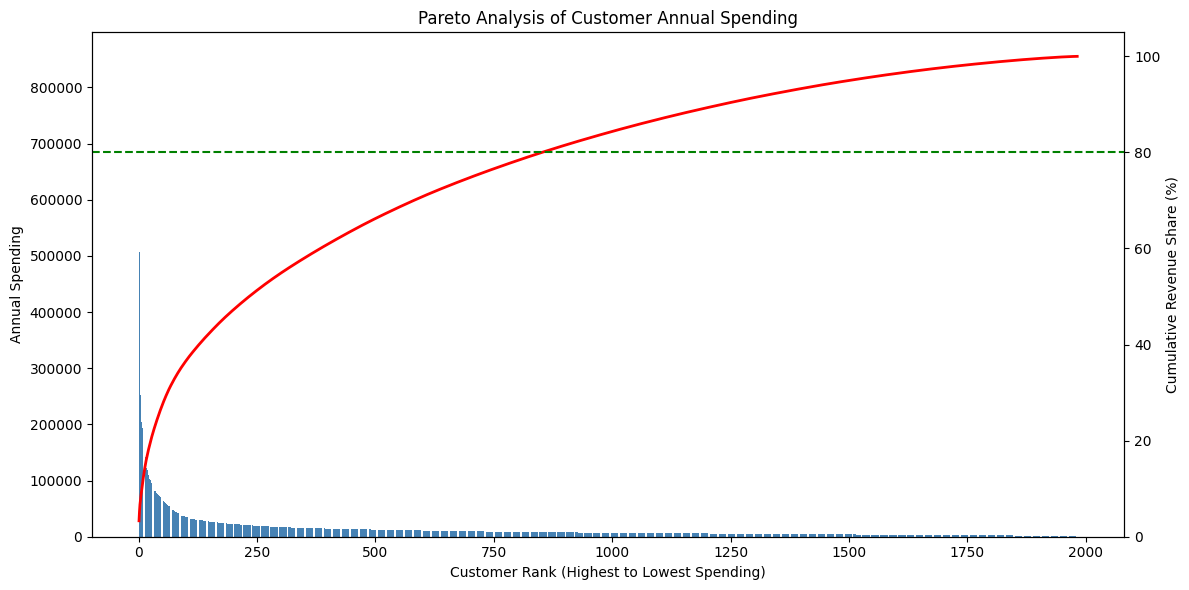

In [133]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot individual customer spending
ax1.bar(
    pareto_df['customer_rank'],
    pareto_df['annual_spend'],
    color='steelblue',
    label='Annual Spend'
)

ax1.set_xlabel('Customer Rank (Highest to Lowest Spending)')
ax1.set_ylabel('Annual Spending')
ax1.set_title('Pareto Analysis of Customer Annual Spending')

# Second axis for cumulative revenue share
ax2 = ax1.twinx()

ax2.plot(
    pareto_df['customer_rank'],
    pareto_df['cumulative_share_pct'],
    color='red',
    linewidth=2,
    label='Cumulative Revenue Share'
)

ax2.axhline(
    80,
    linestyle='--',
    color='green',
    label='80% Revenue'
)

ax2.set_ylabel('Cumulative Revenue Share (%)')
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()


In the graph also we can see 80/20 rule is not applicable as revenue is concentrated in 50-60% of the customers

Ploting annual_spend on a normal scale and a log scale

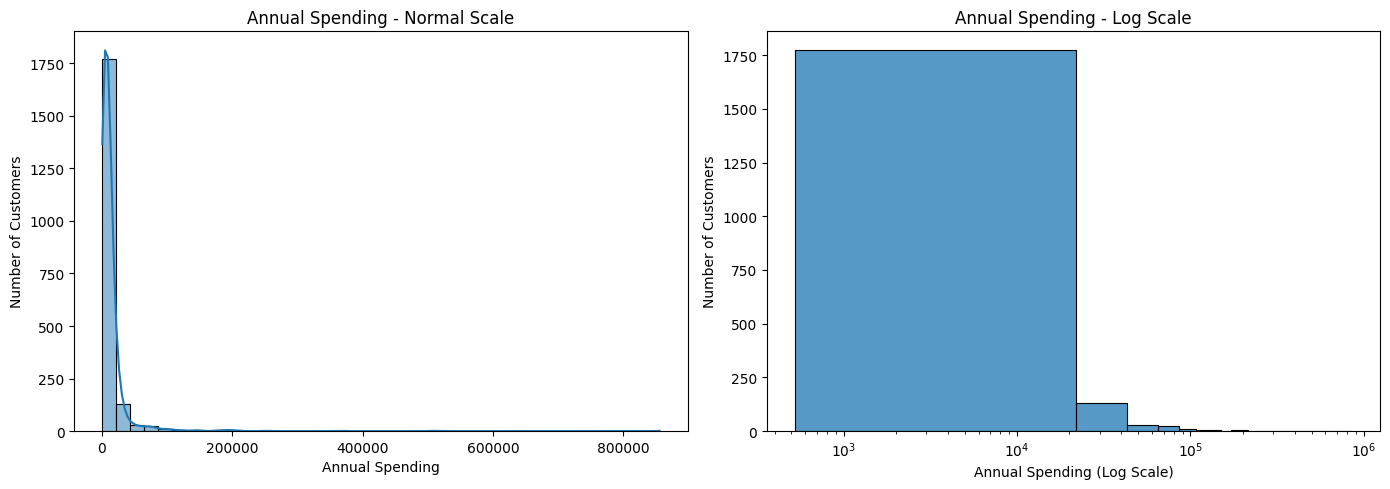

In [137]:
# Remove missing values
spend_data = df['annual_spend'].dropna()

# Keep positive values for logarithmic scale
positive_spend = spend_data[spend_data > 0]

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Normal scale
sns.histplot(
    spend_data,
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Annual Spending - Normal Scale')
axes[0].set_xlabel('Annual Spending')
axes[0].set_ylabel('Number of Customers')

# Logarithmic scale
sns.histplot(
    positive_spend,
    bins=40,
    ax=axes[1]
)

axes[1].set_xscale('log')
axes[1].set_title('Annual Spending - Log Scale')
axes[1].set_xlabel('Annual Spending (Log Scale)')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()


# Step 9- PDF and CDF

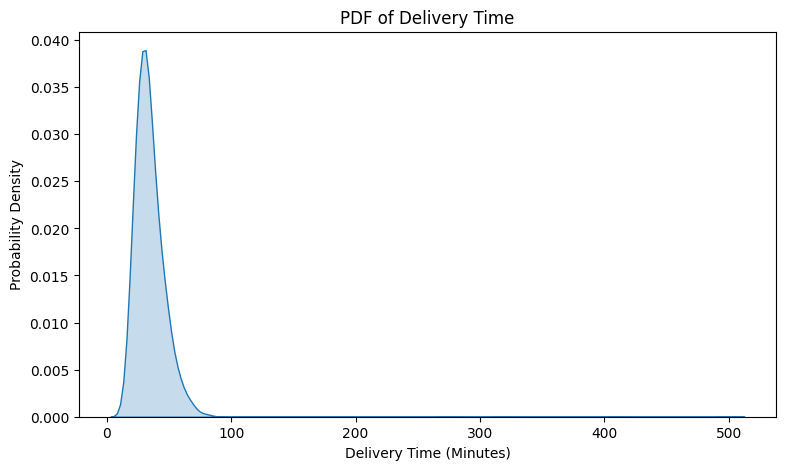

In [138]:
# Remove missing values
delivery = df['delivery_time_min'].dropna()

# Plot PDF using KDE
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=delivery,
    fill=True
)

plt.title('PDF of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Probability Density')

plt.show()


The peak indicates the delivery-time region where observations are most densely concentrated.
The PDF illustrates the distribution of delivery times and identifies the time intervals where deliveries are most concentrated. The peak of the curve indicates the most densely populated delivery-time range.

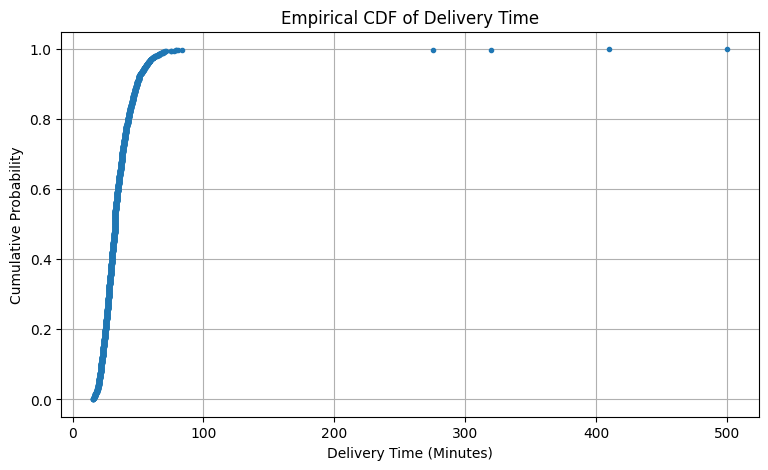

In [139]:

# Sort delivery times
delivery_sorted = np.sort(delivery)

# Number of observations
n = len(delivery_sorted)

# Calculate empirical CDF
cdf = np.arange(1, n + 1) / n

# Plot CDF
plt.figure(figsize=(9, 5))

plt.plot(
    delivery_sorted,
    cdf,
    marker='.',
    linestyle='none'
)

plt.title('Empirical CDF of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Cumulative Probability')

plt.grid(True)
plt.show()


The empirical CDF shows the cumulative proportion of deliveries completed within different time intervals. It helps understand delivery performance at different time thresholds.

In [140]:

# Probability of delivery taking 30 minutes or less
prob_30 = (delivery <= 30).mean()

# Probability of delivery taking more than 45 minutes
prob_45 = (delivery > 45).mean()

# Calculate median (P50)
median_delivery = delivery.quantile(0.50)

# Calculate 95th percentile
p95_delivery = delivery.quantile(0.95)

print("DELIVERY TIME PROBABILITY ANALYSIS")

print(
    f"Probability of delivery <= 30 minutes: "
    f"{prob_30:.4f} ({prob_30*100:.2f}%)"
)

print(
    f"Probability of delivery > 45 minutes: "
    f"{prob_45:.4f} ({prob_45*100:.2f}%)"
)

print(
    f"Median Delivery Time (P50): "
    f"{median_delivery:.2f} minutes"
)

print(
    f"95th Percentile Delivery Time (P95): "
    f"{p95_delivery:.2f} minutes"
)


DELIVERY TIME PROBABILITY ANALYSIS
Probability of delivery <= 30 minutes: 0.3986 (39.86%)
Probability of delivery > 45 minutes: 0.1579 (15.79%)
Median Delivery Time (P50): 32.25 minutes
95th Percentile Delivery Time (P95): 55.40 minutes


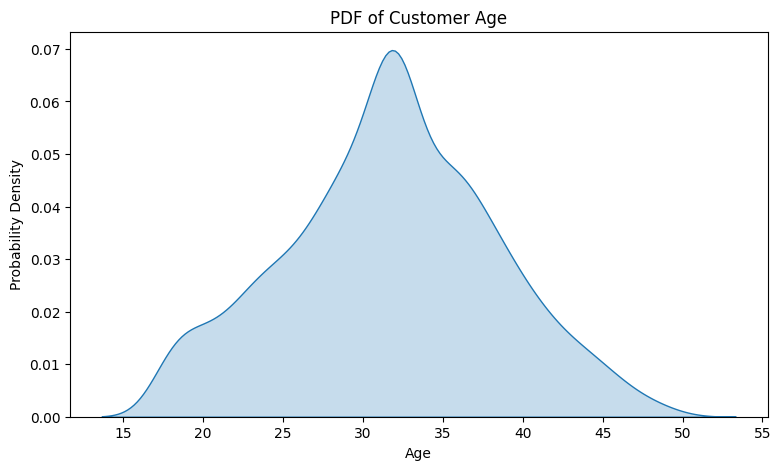

In [141]:

# Remove missing age values
age = df['age'].dropna()

# Plot PDF using KDE
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=age,
    fill=True
)

plt.title('PDF of Customer Age')
plt.xlabel('Age')
plt.ylabel('Probability Density')

plt.show()


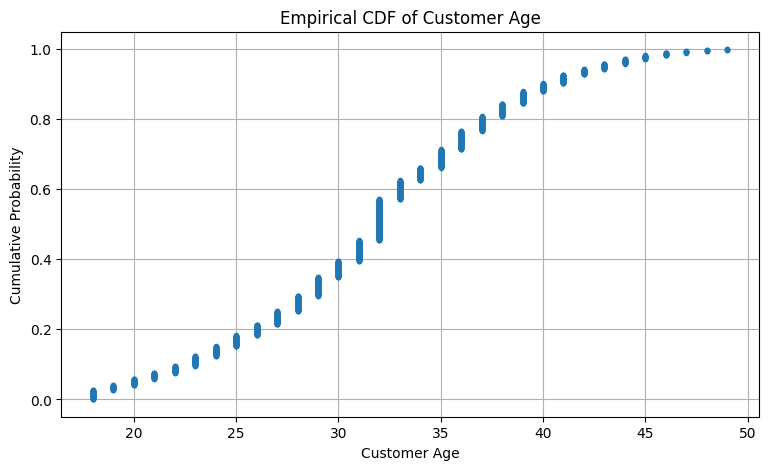

In [142]:

# Sort age values
age_sorted = np.sort(age)

# Number of observations
n_age = len(age_sorted)

# Calculate empirical CDF
cdf_age = np.arange(1, n_age + 1) / n_age

# Plot CDF
plt.figure(figsize=(9, 5))

plt.plot(
    age_sorted,
    cdf_age,
    marker='.',
    linestyle='none'
)

plt.title('Empirical CDF of Customer Age')
plt.xlabel('Customer Age')
plt.ylabel('Cumulative Probability')

plt.grid(True)
plt.show()


The age PDF and CDF provide insights into customer demographics. The PDF identifies age groups with higher customer concentration, while the CDF shows the proportion of customers below or equal to a particular age.

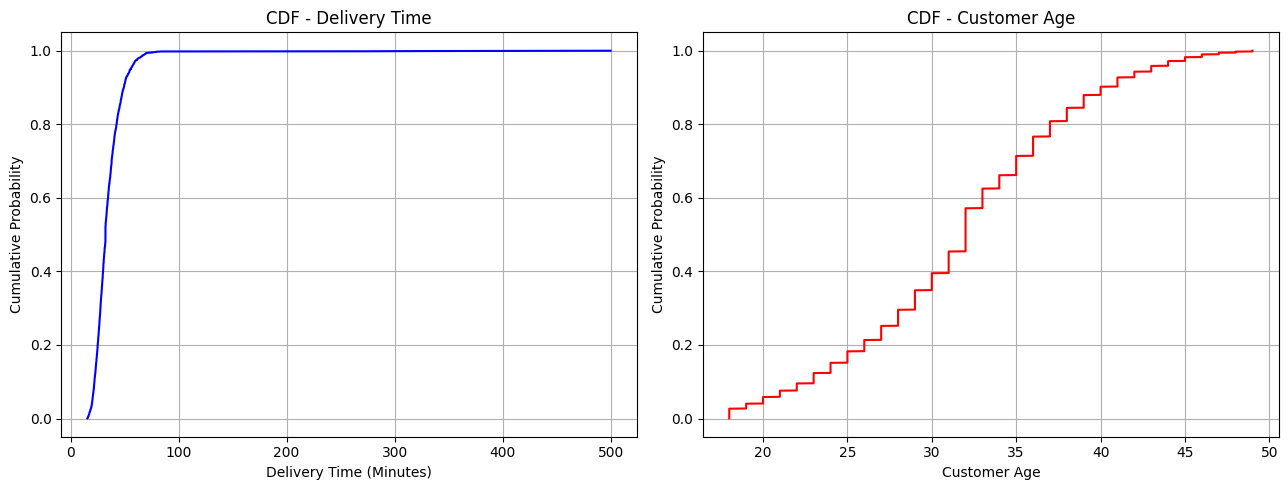

In [143]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Delivery Time CDF
axes[0].plot(delivery_sorted, cdf, color='blue')
axes[0].set_title('CDF - Delivery Time')
axes[0].set_xlabel('Delivery Time (Minutes)')
axes[0].set_ylabel('Cumulative Probability')
axes[0].grid(True)

# Age CDF
axes[1].plot(age_sorted, cdf_age, color='red')
axes[1].set_title('CDF - Customer Age')
axes[1].set_xlabel('Customer Age')
axes[1].set_ylabel('Cumulative Probability')
axes[1].grid(True)

plt.tight_layout()
plt.show()


PDF = how dense values are around a point means- Where are the observations most densely concentrated?

Example: If the PDF has a peak around 30 minutes, many deliveries are concentrated around that time.

CDF = share of values at or below a point means- What proportion of observations is at or below a particular value?

Example: If the CDF at 30 minutes is 0.60, then 60% of deliveries take 30 minutes or less.

TO EXPORT THE CLEAN FILE

In [145]:
from google.colab import files

df.to_csv('quickbite_clean.csv', index=False)

files.download('quickbite_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Insites:
1. A small group of ultra-heavy accounts drives a quarter of revenue.

2. Basic membership users are spending more as compaired to other memberships

3. Slow delivery in Tier 1 cities

4. Missing Ratings are random and are not dependent on late delivery time

5. Revenue concentration is strong, but donot follow  classic 80/20 rule.

